# Fase 4: Visualización y comunicación de resultados

## Proyecto: Factores asociados a la permanencia operativa de startups de Y Combinator

## Objetivo de la Fase 4

Comunicar los principales hallazgos del proyecto mediante visualizaciones analíticas, evaluando si las diferencias entre startups de IA y tradicionales se mantienen dentro de rangos comparables de antigüedad, y examinando cómo la permanencia operativa, la contratación y la adopción de IA varían entre industrias.

## Alcance

Esta fase contempla la integración de los datos procesados, la validación de su estructura para el análisis visual, la elaboración de visualizaciones, la interpretación de resultados, la identificación de limitaciones y la formulación de conclusiones.

El análisis se realizará sobre los datos resultantes de la Fase 3, manteniendo la coherencia metodológica y técnica con las etapas previas del proyecto.

# Lo que dejó F3

La Fase 3 entregó el archivo startups_procesadas.csv, que contiene 6.193 registros y 10 variables. El conjunto fue previamente limpiado y validado, por lo que F4 no repite las transformaciones de datos.

El archivo se utiliza como entrada para las visualizaciones y análisis de esta fase.

In [1]:
# Librerías para análisis y visualización
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

#  Carga y verificación del conjunto procesado


In [3]:
def localizar_raiz():
    carpeta_actual = Path.cwd()

    if carpeta_actual.name in {"F1", "F2", "F3", "F4"}:
        return carpeta_actual.parent

    return carpeta_actual


RAIZ = localizar_raiz()

DIR_PROCESADO = RAIZ / "data" / "processed"
DIR_FIGURAS = RAIZ / "F4" / "figuras"
DIR_DOCS = RAIZ / "docs"

DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_DOCS.mkdir(parents=True, exist_ok=True)

print("Raíz del proyecto:", RAIZ)
print("Datos procesados:", DIR_PROCESADO)
print("Directorio de figuras:", DIR_FIGURAS)

Raíz del proyecto: C:\Users\Casti\U-Andres-Bello\U-Andres-Bello
Datos procesados: C:\Users\Casti\U-Andres-Bello\U-Andres-Bello\data\processed
Directorio de figuras: C:\Users\Casti\U-Andres-Bello\U-Andres-Bello\F4\figuras


In [4]:
RUTA_PROCESADO = (
    DIR_PROCESADO /
    "startups_procesadas.csv"
)

if not RUTA_PROCESADO.exists():
    raise FileNotFoundError(
        "No se encontró el archivo procesado. "
        "Ejecuta primero F3."
    )

df = pd.read_csv(RUTA_PROCESADO)

print("Dimensiones:", df.shape)
print("Valores nulos:", df.isna().sum().sum())

Dimensiones: (6193, 10)
Valores nulos: 0


In [8]:
df

,name,is_operating,is_hiring,nonprofit,status,is_ai,team_size,industry,hq_country,years_since_batch
0,Rote,True,False,False,Active,False,0.0,B2B,USA,0.0
1,Antropi Robotics,True,False,False,Active,False,0.0,Industrials,India,0.0
2,Capveon,True,False,False,Active,False,2.0,Government,USA,0.0
3,Collar,True,False,False,Active,True,2.0,B2B,Singapore,0.0
4,Covera,True,True,False,Active,False,2.0,Fintech,USA,0.0
...,...,...,...,...,...,...,...,...,...,...
6188,Memamp,False,False,False,Inactive,False,0.0,B2B,USA,21.0
6189,Parakey,False,False,False,Acquired,False,2.0,B2B,USA,21.0
6190,Reddit,False,False,False,Acquired,False,2000.0,Consumer,USA,21.0
6191,Simmery,False,False,False,Inactive,False,0.0,Consumer,USA,21.0


# Preparación de variables para el análisis
La antigüedad se agrupó en cuatro tramos para comparar startups con tiempos similares desde su participación en Y Combinator. De esta manera, la antigüedad se utiliza como variable de control en las comparaciones entre startups de IA y tradicionales.

In [10]:
df["tramo_antiguedad"] = pd.cut(
    df["years_since_batch"],
    bins=[-1, 2, 5, 10, float("inf")],
    labels=[
        "0-2 años",
        "3-5 años",
        "6-10 años",
        "11+ años"
    ]
)

df["tipo_startup"] = df["is_ai"].map({
    True: "IA",
    False: "Tradicional"
})

df[
    [
        "tipo_startup",
        "tramo_antiguedad",
        "industry",
        "is_operating",
        "is_hiring"
    ]
].head()

,tipo_startup,tramo_antiguedad,industry,is_operating,is_hiring
0,Tradicional,0-2 años,B2B,True,False
1,Tradicional,0-2 años,Industrials,True,False
2,Tradicional,0-2 años,Government,True,False
3,IA,0-2 años,B2B,True,False
4,Tradicional,0-2 años,Fintech,True,True


# Pregunta 1

¿Existe una diferencia en la permanencia operativa entre startups relacionadas con inteligencia artificial y startups tradicionales en el mismo rango de antigüedad?


In [22]:
permanencia = (

    df
    .groupby(
        [
            "tramo_antiguedad",
            "tipo_startup"
        ],
        observed=True
    )
    .agg(
        proporcion_operativa=(
            "is_operating",
            "mean"
        ),
        cantidad=(
            "is_operating",
            "size"
        )
    )
    .reset_index()

)

permanencia

,tramo_antiguedad,tipo_startup,proporcion_operativa,cantidad
0,0-2 años,IA,0.953101,661
1,0-2 años,Tradicional,0.965947,1204
2,3-5 años,IA,0.790323,496
3,3-5 años,Tradicional,0.745026,1357
4,6-10 años,IA,0.683938,193
5,6-10 años,Tradicional,0.533530,1357
6,11+ años,IA,0.583333,36
7,11+ años,Tradicional,0.269966,889


C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be 

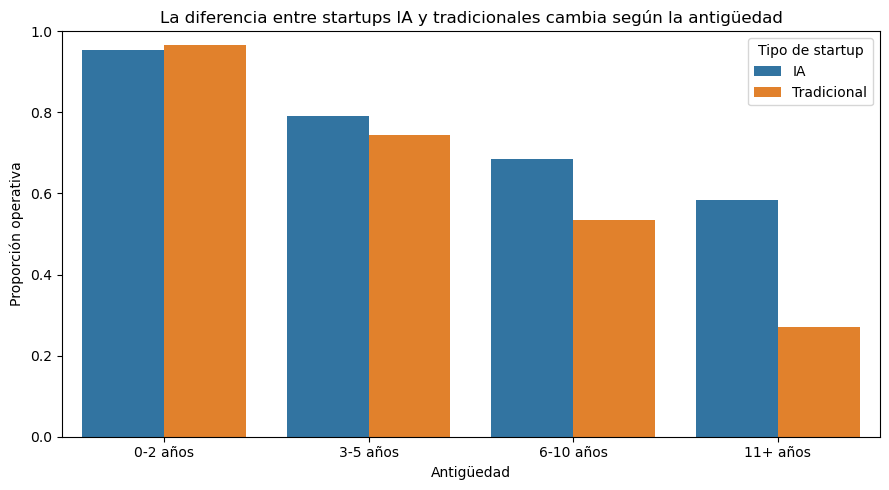

In [23]:
plt.figure(figsize=(9,5))

sns.barplot(

    data=permanencia,

    x="tramo_antiguedad",

    y="proporcion_operativa",

    hue="tipo_startup"

)

plt.ylim(0,1)

plt.xlabel(
    "Antigüedad"
)

plt.ylabel(
    "Proporción operativa"
)

plt.title(
    "La diferencia entre startups IA y tradicionales cambia según la antigüedad"
)

plt.legend(
    title="Tipo de startup"
)

plt.tight_layout()

plt.show()

In [21]:
permanencia = (
    df
    .groupby(
        ["tramo_antiguedad", "tipo_startup"],
        observed=True
    )
    .agg(
        operativas=("is_operating", "sum"),
        total=("is_operating", "size"),
        proporcion=("is_operating", "mean")
    )
    .reset_index()
)
permanencia

,tramo_antiguedad,tipo_startup,operativas,total,proporcion
0,0-2 años,IA,630,661,0.953101
1,0-2 años,Tradicional,1163,1204,0.965947
2,3-5 años,IA,392,496,0.790323
3,3-5 años,Tradicional,1011,1357,0.745026
4,6-10 años,IA,132,193,0.683938
5,6-10 años,Tradicional,724,1357,0.533530
6,11+ años,IA,21,36,0.583333
7,11+ años,Tradicional,240,889,0.269966


### Análisis Figura 1: Las startups de IA presentan una mayor permanencia operativa

La diferencia observada entre startups de IA y tradicionales no es uniforme en todos los tramos de antigüedad. En las empresas más recientes (0 a 2 años) las tasas operativas son prácticamente iguales, mientras que en los tramos de mayor antigüedad la diferencia aumenta a favor de las startups relacionadas con inteligencia artificial.

Las empresas dedicadas a IA muestran mayor continuidad operacional en tramos de mayor antigüedad, sin embargo, esto se debe a que son startups más recientes, la cantidad de la muestra es mucho menor, por ende el resultado puede desvirtuarse. Aún así, en tramos recientes de igual manera muestran un buen porcentaje de continuidad, dado que la tecnología sigue avanzando y las compañías requieren automatizaciones de sus procesos.

# Pregunta 2
¿Las startups de IA muestran una mayor actividad de contratación que las tradicionales dentro de rangos comparables de antigüedad?

In [27]:
contratacion = (

    df
    .groupby(
        [
            "tramo_antiguedad",
            "tipo_startup"
        ],
        observed=True
    )
    .agg(
        contratando=("is_hiring", "sum"),
        total=("is_hiring", "size"),
        proporcion=("is_hiring", "mean")
    )
    .reset_index()

)

contratacion["porcentaje"] = (
    contratacion["proporcion"] * 100
).round(1)

contratacion


,tramo_antiguedad,tipo_startup,contratando,total,proporcion,porcentaje
0,0-2 años,IA,216,661,0.326778,32.7
1,0-2 años,Tradicional,406,1204,0.337209,33.7
2,3-5 años,IA,168,496,0.338710,33.9
3,3-5 años,Tradicional,325,1357,0.239499,23.9
4,6-10 años,IA,66,193,0.341969,34.2
5,6-10 años,Tradicional,229,1357,0.168755,16.9
6,11+ años,IA,9,36,0.250000,25.0
7,11+ años,Tradicional,62,889,0.069741,7.0


C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be 

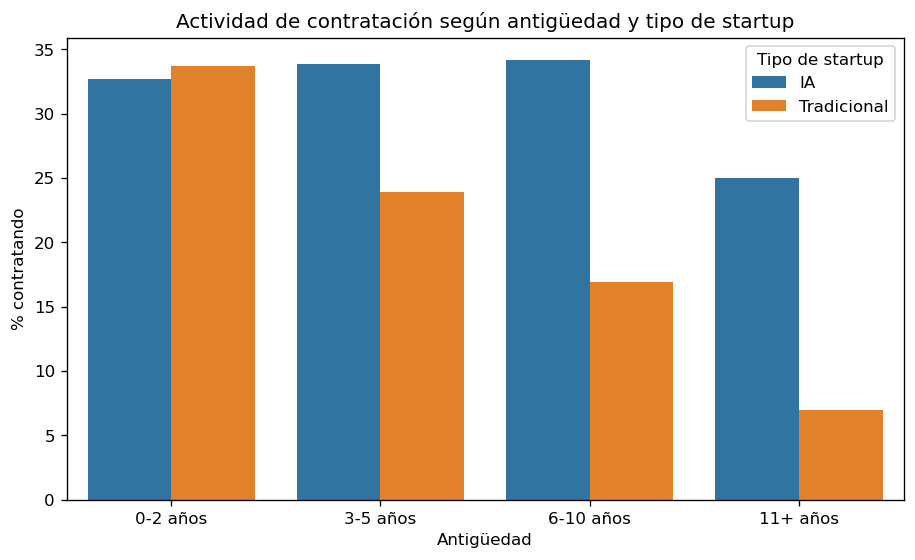

In [32]:
plt.figure(figsize=(9,5))

sns.barplot(

    data=contratacion,

    x="tramo_antiguedad",

    y="porcentaje",

    hue="tipo_startup"

)

plt.xlabel(
    "Antigüedad"
)

plt.ylabel(
    "% contratando"
)

plt.title(
    "Actividad de contratación según antigüedad y tipo de startup"
)

plt.legend(
    title="Tipo de startup"
)

plt.show()

# Análisis Figura 2

La actividad de contratación disminuye a medida que aumenta la antigüedad de las startups. Sin embargo, al comparar empresas dentro de los mismos tramos de edad, las startups relacionadas con inteligencia artificial presentan una mayor proporción de contratación en la mayoría de los grupos analizados.

La diferencia es especialmente visible en los tramos de 6 a 10 años y de más de 11 años, donde la proporción de empresas contratando es considerablemente mayor entre las startups de IA. Estos resultados sugieren que las startups relacionadas con inteligencia artificial muestran señales de expansión más frecuentes que las startups tradicionales, aunque las diferencias deben interpretarse considerando el tamaño de cada grupo analizado.